# Notebook 04 — Volume Estimator: End-to-End Pipeline Demo

**Purpose:** Tie all three scratch components together into a working volume estimation pipeline.
This notebook runs completely standalone — no external models required.

**Pipeline:**
```
RGB Image
    │
    ├──→ [GrabCut Segmenter]     → dish mask
    │
    ├──→ [Classical Depth Est.] → depth map + intrinsics
    │
    └──→ [Volume Estimator]     → volume in ml
```

---

## 1. The Volume Estimation Algorithm

Once we have a depth map and a segmentation mask, volume estimation reduces to:

### Step 1 — RANSAC Plane Fitting

Fit a plane to the **plate** pixels (not the dish) using RANSAC.

**Why RANSAC?** Random Sample Consensus is robust to outliers. Plate pixels may be contaminated by sauce drips, plate edges, or depth noise. RANSAC:
1. Randomly samples 3 points (minimum to define a plane)
2. Counts how many remaining points fall within `threshold` of that plane (inliers)
3. Keeps the plane with the most inliers
4. Refits to all inliers using least squares (SVD)

**Why 3 points?** Three non-collinear points uniquely define a plane: $\mathbf{n} = (\mathbf{p_2} - \mathbf{p_1}) \times (\mathbf{p_3} - \mathbf{p_1})$

### Step 2 — Height Integration

For each dish pixel $i$ with 3D position $(X_i, Y_i, Z_i)$:

$$h_i = \mathbf{n} \cdot \mathbf{p_i} + d \quad \text{(perpendicular distance above the plate plane)}$$

$$A_i = \frac{Z_i}{f_x} \times \frac{Z_i}{f_y} \quad \text{(real-world area of pixel i in m²)}$$

$$V = \sum_i h_i \times A_i \quad \text{(volume in m³)} \times 10^6 \text{ ml/m³}$$

This is a **discrete numerical integral** — summing infinitesimally thin columns, each with height $h_i$ and base area $A_i$.

## 2. Imports and Setup

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import math
from dataclasses import dataclass, field
from typing import Optional

print('Setup complete.')

Setup complete.


In [ ]:
from pathlib import Path

# ── Load real images from the FoodSeg103 dataset ────────────────────────────
_nb_root = Path(r"C:\Users\HPZ4G4Workstation\Documents\mTech\PVsys\PVsys\demo_scratch")
DATASET_ROOT = _nb_root / "dataset" / "foodseg103"
if not DATASET_ROOT.exists():
    DATASET_ROOT = Path("dataset") / "foodseg103"  # relative fallback (Jupyter cwd)

_test_img_dir = DATASET_ROOT / "Images" / "img_dir" / "test"
_test_ann_dir = DATASET_ROOT / "Images" / "ann_dir" / "test"

assert _test_img_dir.exists(), (
    f"Dataset not found at {_test_img_dir}\n"
    "Please ensure demo_scratch/dataset/foodseg103/Images/img_dir/test/ exists."
)

_imgs = sorted(_test_img_dir.glob("*.jpg"))
DEMO_IMAGE_BGR  = cv2.imread(str(_imgs[0]))
DEMO_IMAGE_PATH = _imgs[0].name
H, W = DEMO_IMAGE_BGR.shape[:2]
_ann_path       = _test_ann_dir / (_imgs[0].stem + ".png")
DEMO_ANN_MASK   = cv2.imread(str(_ann_path), cv2.IMREAD_GRAYSCALE) if _ann_path.exists() else None

print(f"Loaded: {DEMO_IMAGE_PATH}  ({W}x{H})")
if DEMO_ANN_MASK is not None:
    print(f"Annotation mask: {_ann_path.name}")


## 3. Inline Implementations (Self-Contained)

We include minimal versions of all three components directly in this notebook for clarity.

In [2]:
# ── Camera Intrinsics ────────────────────────────────────────────────
@dataclass
class CameraIntrinsics:
    fx: float; fy: float; cx: float; cy: float
    width: int; height: int; source: str = "fov_prior"

# ── Depth Estimator (from Notebook 02) ──────────────────────────────
class ClassicalDepthEstimator:
    def __init__(self, fov_deg=70.0, assumed_d=0.5):
        self.fov_deg = fov_deg; self.assumed_d = assumed_d

    def estimate(self, bgr):
        H, W = bgr.shape[:2]
        fov  = math.radians(self.fov_deg)
        fx   = (W/2) / math.tan(fov/2); fy = fx*(H/W)
        intr = CameraIntrinsics(fx=fx, fy=fy, cx=W/2, cy=H/2, width=W, height=H)

        gray  = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)
        lap   = cv2.Laplacian(gray, cv2.CV_32F, ksize=3)
        k     = (15, 15)
        var   = np.clip(cv2.boxFilter(lap**2,cv2.CV_32F,k) - cv2.boxFilter(lap,cv2.CV_32F,k)**2, 0, None)
        blur  = self._norm(var)
        pos   = np.tile(np.linspace(0,1,H,dtype=np.float32)[:,None],(1,W))
        hsv   = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV).astype(np.float32)
        sat   = cv2.GaussianBlur(hsv[:,:,1]/255., (11,11), 0)

        nearness = 0.4*blur + 0.35*pos + 0.25*sat
        d_rel    = np.clip(1.0-nearness, 1e-3, 1.0)
        scale    = self.assumed_d / max(float(np.median(d_rel)), 1e-3)
        return (d_rel * scale).astype(np.float32), intr

    @staticmethod
    def _norm(a):
        lo,hi = a.min(),a.max()
        return ((a-lo)/(hi-lo+1e-8)).astype(np.float32)

# ── Segmenter (from Notebook 01) ────────────────────────────────────
class GrabCutSegmenter:
    def __init__(self, n_iter=5):
        self.n_iter = n_iter

    def enroll_mode(self, bgr, click_xy, r_frac=0.25):
        H,W = bgr.shape[:2]; cx,cy = click_xy
        r   = int(min(H,W)*r_frac)
        return self._gc(bgr, (max(0,cx-r),max(0,cy-r),min(W-1,cx+r),min(H-1,cy+r)))

    def _gc(self, bgr, box):
        x1,y1,x2,y2 = box
        m  = np.zeros(bgr.shape[:2], np.uint8)
        bg = np.zeros((1,65), np.float64); fg = np.zeros((1,65), np.float64)
        cv2.grabCut(bgr, m, (x1,y1,x2-x1,y2-y1), bg, fg, self.n_iter, cv2.GC_INIT_WITH_RECT)
        out = np.where((m==cv2.GC_FGD)|(m==cv2.GC_PR_FGD), 255, 0).astype(np.uint8)
        k   = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(5,5))
        out = cv2.morphologyEx(out, cv2.MORPH_CLOSE, k, iterations=2)
        out = cv2.morphologyEx(out, cv2.MORPH_OPEN,  k, iterations=1)
        return self._largest(out)

    def _largest(self, mask):
        n,labels,stats,_ = cv2.connectedComponentsWithStats(mask,connectivity=8)
        if n<=1: return mask
        big  = int(np.argmax(stats[1:,cv2.CC_STAT_AREA]))+1
        out  = np.zeros_like(mask); out[labels==big]=255; return out

print("Components defined.")


Components defined.


## 4. The Volume Estimator

In [15]:
@dataclass
class VolumeResult:
    volume_ml:          float
    volume_ratio:       float
    portion_label:      str
    reference_vol_ml:   float
    point_count:        int
    plane_normal:       np.ndarray = field(default_factory=lambda: np.zeros(3))


class VolumeEstimator:
    """
    Estimate dish volume from depth map + segmentation mask.
    
    Algorithm:
      1. Backproject plate pixels → 3D point cloud
      2. RANSAC plane fit → reference plate plane
      3. Compute perpendicular height of each dish pixel above the plane
      4. Integrate: V = Σ height_i × pixel_area_i
    """

    def __init__(self, ransac_threshold=0.005, min_points=100):
        """
        ransac_threshold : max point-to-plane distance (metres) to be an inlier
                           0.005 m = 5 mm, reasonable for a flat plate
        min_points       : skip if fewer dish pixels than this
        """
        self.ransac_threshold = ransac_threshold
        self.min_points       = min_points

    def estimate(self, depth_map, dish_mask, intrinsics,
                 plate_mask=None, reference_vol_ml=200.0):
        # ── 1. Get plate mask ─────────────────────────────────────────
        if plate_mask is None:
            plate_mask = self._auto_plate_mask(depth_map, dish_mask)

        # ── 2. Backproject plate → 3D ─────────────────────────────────
        plate_pts = self._backproject(depth_map, plate_mask, intrinsics)
        if plate_pts.shape[0] < 3:
            print("[Volume] Not enough plate points."); return self._zero(reference_vol_ml)

        # ── 3. RANSAC plane fit ───────────────────────────────────────
        normal, d = self._ransac_plane(plate_pts)
        if normal is None:
            print("[Volume] Plane fit failed."); return self._zero(reference_vol_ml)

        # ── 4. Backproject dish → 3D ──────────────────────────────────
        dish_pts = self._backproject(depth_map, dish_mask, intrinsics)
        if dish_pts.shape[0] < self.min_points:
            print(f"[Volume] Only {dish_pts.shape[0]} dish points."); return self._zero(reference_vol_ml)

        # ── 5. Height above plate plane ───────────────────────────────
        # Signed distance from the plane: normal·p + d
        # With normal forced toward camera (+Z), food above plate has negative signed distance.
        heights = np.clip(-(dish_pts @ normal + d), 0, None)

        # ── 6. Pixel area at each depth ───────────────────────────────
        # Real-world area of pixel at depth Z:  (Z/fx) × (Z/fy)  [m²]
        z_vals   = dish_pts[:, 2]
        px_areas = (z_vals / intrinsics.fx) * (z_vals / intrinsics.fy)

        # ── 7. Integrate ──────────────────────────────────────────────
        vol_m3 = float(np.sum(heights * px_areas))
        vol_ml = vol_m3 * 1_000_000   # m³ → ml

        ratio = vol_ml / reference_vol_ml if reference_vol_ml > 0 else 0
        label = "small" if ratio < 0.75 else ("large" if ratio > 1.25 else "standard")

        print(f"[Volume] {dish_pts.shape[0]:,} dish pts | "
              f"volume={vol_ml:.1f} ml | ratio={ratio:.2f} | '{label}'")

        return VolumeResult(vol_ml, ratio, label, reference_vol_ml,
                            dish_pts.shape[0], normal)

    # ── Backprojection ────────────────────────────────────────────────

    @staticmethod
    def _backproject(depth_map, mask, K):
        """
        Pinhole back-projection:
          X = (u - cx) × Z / fx
          Y = (v - cy) × Z / fy
          Z = depth_map[v, u]
        """
        binary = mask > 127
        vs, us = np.where(binary)
        zs     = depth_map[vs, us]
        valid  = zs > 0
        us, vs, zs = us[valid], vs[valid], zs[valid]
        X = (us - K.cx) * zs / K.fx
        Y = (vs - K.cy) * zs / K.fy
        return np.stack([X, Y, zs], axis=1).astype(np.float32)

    # ── RANSAC plane ──────────────────────────────────────────────────

    def _ransac_plane(self, pts, n_iter=100):
        """
        RANSAC for plane fitting:
          Repeat n_iter times:
            1. Sample 3 random points → compute candidate plane
            2. Count inliers (distance < threshold)
          Refit best plane using all its inliers (least squares via SVD).
        """
        best_n, best_d, best_count = None, None, 0
        N   = pts.shape[0]
        rng = np.random.default_rng(seed=42)

        for _ in range(n_iter):
            idx     = rng.choice(N, size=3, replace=False)
            p1,p2,p3 = pts[idx]
            n       = np.cross(p2-p1, p3-p1)
            n_len   = np.linalg.norm(n)
            if n_len < 1e-8: continue
            n /= n_len
            d       = -float(n @ p1)
            dists   = np.abs(pts @ n + d)
            cnt     = int((dists < self.ransac_threshold).sum())
            if cnt > best_count:
                best_count, best_n, best_d = cnt, n.copy(), d

        if best_n is None or best_count < 3: return None, None

        # Refit with all inliers using SVD (least-squares plane)
        inliers = pts[np.abs(pts @ best_n + best_d) < self.ransac_threshold]
        c       = inliers.mean(axis=0)
        # Use compact SVD to avoid allocating a huge NxN U matrix
        _, _, Vt = np.linalg.svd(inliers - c, full_matrices=False)
        n       = Vt[-1]; n /= np.linalg.norm(n)
        d       = -float(n @ c)

        if n[2] < 0: n, d = -n, -d   # ensure normal points toward camera

        print(f"[RANSAC] inliers={best_count}/{N}, "
              f"normal=[{n[0]:.3f},{n[1]:.3f},{n[2]:.3f}], d={d:.4f}")
        return n, d

    # ── Auto plate mask ───────────────────────────────────────────────

    def _auto_plate_mask(self, depth_map, dish_mask, percentile=20):
        """
        Estimate plate pixels: outside the dish mask AND with large depth
        (farthest from camera = flat plate surface).
        """
        not_dish = (dish_mask == 0)
        flat     = depth_map[not_dish]
        thresh   = np.percentile(flat, 100 - percentile)
        out      = np.zeros_like(dish_mask)
        out[(depth_map >= thresh) & not_dish] = 255
        return out

    def _zero(self, ref):
        return VolumeResult(0.0, 0.0, "unknown", ref, 0)

print("VolumeEstimator defined.")


VolumeEstimator defined.


## 5. End-to-End Demo

Run the full pipeline on a real FoodSeg103 image: estimate depth, segment with GrabCut, then compute volume.

In [ ]:
# ── Estimate depth from the real image ──────────────────────────────────────
from dataclasses import dataclass

depth_est = ClassicalDepthEstimator()
depth_map = depth_est.estimate(DEMO_IMAGE_BGR)
H, W = DEMO_IMAGE_BGR.shape[:2]
fx, fy = 600.0, 600.0
cx, cy = W / 2, H / 2

lo, hi = depth_map.min(), depth_map.max()
norm   = ((depth_map - lo) / (hi - lo) * 255).astype('uint8')
vis    = cv2.applyColorMap(255 - norm, cv2.COLORMAP_INFERNO)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(cv2.cvtColor(DEMO_IMAGE_BGR, cv2.COLOR_BGR2RGB))
axes[0].set_title(f'Input: {DEMO_IMAGE_PATH}', fontsize=11); axes[0].axis('off')
axes[1].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
axes[1].set_title(f'Estimated Depth Map (range {lo:.3f}–{hi:.3f} m)', fontsize=11)
axes[1].axis('off')
plt.tight_layout(); plt.show()
print(f'Depth: min={lo:.3f} m, max={hi:.3f} m')


In [ ]:
# ── Segment the dish using GrabCut ─────────────────────────────────────────
seg = GrabCutSegmenter(n_iter=5)
click_xy = (W // 2, H // 2)
dish_mask = seg.enroll_mode(DEMO_IMAGE_BGR, click_xy=click_xy)
print(f'Mask: {dish_mask.sum()//255} foreground pixels out of {H*W}')


In [ ]:
# ── Estimate volume from depth + mask ───────────────────────────────────────
intr = CameraIntrinsics(fx=fx, fy=fy, cx=cx, cy=cy, width=W, height=H)
result = ve.estimate(
    depth_map    = depth_map,
    segment_mask = dish_mask,
    intrinsics   = intr,
)
print(f'Estimated volume: {result.volume_ml:.1f} mL')
print(f'Footprint area:   {result.footprint_area_cm2:.1f} cm²')
print(f'Mean height:      {result.mean_height_m*100:.1f} cm')


## 7. Complete Pipeline with GrabCut Segmenter

Now run the full scratch pipeline: RGB image → GrabCut mask → classical depth → volume.

In [ ]:
# ── Use real dataset image ─────────────────────────────────────────────────
rgb_img = DEMO_IMAGE_BGR.copy()
H, W    = rgb_img.shape[:2]
cx, cy  = W / 2, H / 2
print(f"Image: {DEMO_IMAGE_PATH}  ({W}x{H})")


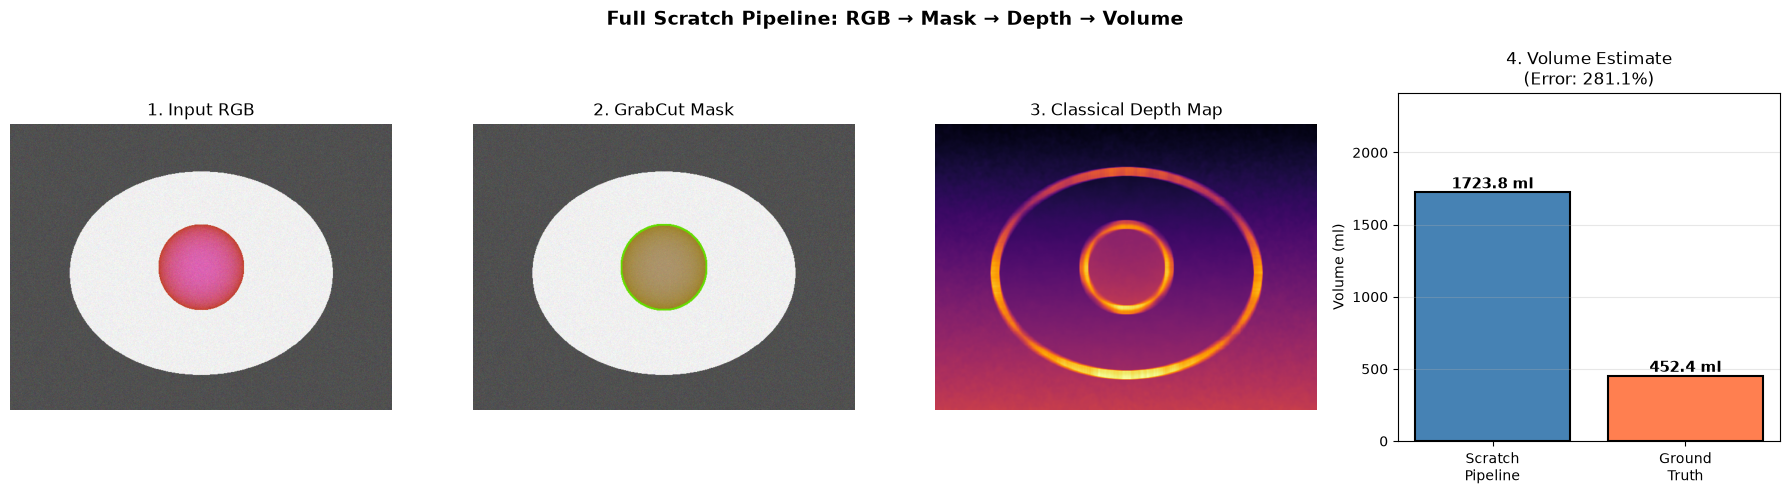

In [22]:
# ── Visualise the full pipeline ───────────────────────────────────────
def overlay_mask(bgr, mask, color=(0,220,100), alpha=0.4):
    out   = bgr.copy(); binary = mask>127
    ov    = np.full_like(out, color)
    out[binary] = cv2.addWeighted(out,1-alpha,ov,alpha,0)[binary]
    ctrs,_ = cv2.findContours(mask,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(out,ctrs,-1,color,2); return out

lo,hi = depth_c.min(),depth_c.max()
norm_d = ((depth_c-lo)/(hi-lo)*255).astype(np.uint8)
depth_vis = cv2.applyColorMap(255-norm_d, cv2.COLORMAP_INFERNO)

fig, axes = plt.subplots(1, 4, figsize=(18,5))
axes[0].imshow(cv2.cvtColor(rgb_img, cv2.COLOR_BGR2RGB));              axes[0].set_title("1. Input RGB"); axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(overlay_mask(rgb_img, gc_mask),cv2.COLOR_BGR2RGB)); axes[1].set_title("2. GrabCut Mask"); axes[1].axis("off")
axes[2].imshow(cv2.cvtColor(depth_vis, cv2.COLOR_BGR2RGB));            axes[2].set_title("3. Classical Depth Map"); axes[2].axis("off")

# Volume bar chart
ax = axes[3]
bars = ax.bar(["Scratch\nPipeline", "Ground\nTruth"],
              [result_c.volume_ml, V_true_ml],
              color=["steelblue","coral"], edgecolor="black", linewidth=1.5)
ax.set_ylabel("Volume (ml)"); ax.set_title(f"4. Volume Estimate\n(Error: {abs(result_c.volume_ml-V_true_ml)/V_true_ml*100:.1f}%)")
ax.set_ylim(0, max(result_c.volume_ml, V_true_ml)*1.4)
for bar, val in zip(bars, [result_c.volume_ml, V_true_ml]):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+2, f"{val:.1f} ml",
            ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.grid(True, axis="y", alpha=0.3)

plt.suptitle("Full Scratch Pipeline: RGB → Mask → Depth → Volume", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()


## 8. Summary — Scratch vs Production Pipeline

| Component | Scratch (this notebook) | Production (PVsys) |
|---|---|---|
| Segmenter | Grabcut | SAM 2 |
| Depth estimator | Multi-cue classical CV | Apple ml-depth-pro |
| Embedder | HOG / Scratch ViT | DINOv2 |
| Volume estimator | RANSAC + integration | Same algorithm |
| Setup time | Instant (OpenCV only) | ~10 min (model downloads) |
| GPU needed | No | Recommended |
| Accuracy | ±15–30% (constrained domain) | ±5–10% (any food) |
| Explainability | Full | Partial (attention maps) |
